<a href="https://colab.research.google.com/github/ramiro-ing/DL-breast-cancer/blob/cambio_nacho_24102026/Obligatorio_implementaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Obligatorio - Taller de Deep Learning

**Fecha de entrega:** 8/12/2026 hasta las 21:00 (hora de Montevideo). Es también el cierre de la competencia en Kaggle (último envío).
**Puntaje máximo:** 50 puntos

**Integrantes:** [Nombre(s) y Apellido(s)]

## Obligatorio

El objetivo de este obligatorio es evaluar su conocimiento en Deep Learning mediante la implementación completa de un modelo de segmentación de imágenes basado en el paper [**"U-Net: Convolutional Networks for Biomedical Image Segmentation"**](https://arxiv.org/pdf/1505.04597). Toda la implementación debe realizarse desde cero utilizando PyTorch, y los estudiantes tendrán la libertad de ajustar ciertos hiperparámetros y configuraciones mientras mantengan la esencia del paper original.

La tarea de este año es la **segmentación de lesiones mamarias en imágenes de ecografía**: para cada imagen, el modelo debe indicar qué píxeles pertenecen a la lesión.

### **Competencia en Kaggle**

Además, como parte de este obligatorio, participarán en una competencia privada en Kaggle donde se les proporcionará un dataset de test oculto (sin target). Deberán subir sus predicciones a Kaggle y se evaluarán en función de la métrica **Dice Coefficient (Coeficiente de Dice)**. Esta competencia les permitirá comparar sus resultados con los de sus compañeros en un entorno real de evaluación.

Las imágenes de test **provienen de otros centros y fueron adquiridas con otros ecógrafos** que las imágenes de entrenamiento. Por lo tanto, un buen resultado en validación no garantiza un buen resultado en test: el modelo debe **generalizar a un dominio distinto** del que vio durante el entrenamiento.

### **¿Qué es el Dice Coefficient?**
El **Dice Coefficient**, también conocido como F1-score para segmentación, es una métrica utilizada para evaluar la similitud entre la predicción y la anotación manual en tareas de segmentación. Se define de la siguiente manera:

$$
\text{Dice} = \frac{2 \cdot |A \cap B|}{|A| + |B|}
$$

Donde:
- $A$ es el conjunto de píxeles predichos como pertenecientes a la clase positiva.
- $B$ es el conjunto de píxeles verdaderos pertenecientes a la clase positiva.
- $|A \cap B|$ es la intersección de $A$ y $B$, es decir, los píxeles correctamente predichos como positivos.

Un valor de Dice de **1** indica una predicción perfecta, mientras que un valor de **0** indica que no hay coincidencia entre la predicción y el valor verdadero. En la competencia, el Dice se calcula **por imagen** y luego se promedia sobre las imágenes de test. Todas las imágenes de test contienen una lesión, por lo que **la predicción de cada imagen debe tener al menos un píxel de lesión**: si alguna fila tiene la máscara vacía, Kaggle rechaza el envío completo. Para aprobar el obligatorio es necesario obtener un puntaje de al menos **0.65** en la tabla pública de Kaggle.

### **Criterios a Evaluar**

1. **Análisis del Dataset (5 puntos):**
   - Exploración y visualización del dataset para comprender su estructura y características (tamaños de imagen, proporción de píxeles de lesión, pacientes, equipos de adquisición, etc.).
   - Comparación entre los equipos de adquisición del conjunto de entrenamiento, e identificación de las diferencias que pueden afectar al modelo cuando se aplique a imágenes de otros equipos.
   - Justificación de las decisiones tomadas en el preprocesamiento de datos, como el tamaño de entrada del modelo, la normalización, el aumento de datos (data augmentation) y la partición del dataset en conjuntos de entrenamiento y validación.

2. **Implementación Correcta del Modelo U-Net (20 puntos):**
   - Construcción de la arquitectura U-Net siguiendo la estructura descrita en el paper, permitiendo ajustes como el número de filtros, funciones de activación y métodos de inicialización de pesos.
   - Se aceptan mejoras, por ejemplo batch normalization u otras funciones de activación.

3. **Entrenamiento del Modelo (10 puntos):**
   - Configuración adecuada del ciclo de entrenamiento, incluyendo la elección de la función de pérdida y del optimizador (Adam, SGD, etc.).
   - Uso de técnicas de regularización para mejorar la generalización del modelo, como el dropout, batch normalization y data augmentation.
   - Gráficas y análisis de la evolución del entrenamiento, mostrando las curvas de pérdida y métricas relevantes tanto en el conjunto de entrenamiento como en el de validación.
   - Puede utilizarse experimentación con hiperparámetros con Weights & Biases (W&B) para optimizar el rendimiento del modelo. Este punto es opcional, pero se valorará positivamente si se justifica su uso y se presentan resultados claros.

4. **Evaluación de Resultados (10 puntos):**
   - Evaluación exhaustiva del modelo utilizando métricas de segmentación como **Dice Coefficient**.
   - Análisis detallado de los resultados, incluyendo un análisis de errores para identificar y discutir casos difíciles.
   - Análisis del efecto del cambio de dominio: qué tipo de imágenes o lesiones se segmentan peor y por qué.
   - Visualización de ejemplos representativos de segmentaciones correctas e incorrectas, comparando con las etiquetas manuales proporcionadas en el dataset.

5. **Participación y Resultados en la Competencia Kaggle (5 puntos):**
   - Participación activa en la competencia de Kaggle, con al menos un (1) envío de predicciones.
   - Puntaje obtenido en la tabla de posiciones de Kaggle, evaluado en base al **Dice Coefficient** en el conjunto de test oculto. Es necesario obtener al menos **0.65** en la tabla pública para aprobar el obligatorio.

   Notas:
   - **Cualquier decisión debe ser justificada en el notebook.**
   - El **Dice Coefficient** es la métrica utilizada para evaluar el desempeño de los modelos de segmentación en esta competencia.

### **Run-Length Encoding (RLE)**

Dado que no se suben las imágenes segmentadas directamente a Kaggle, se requiere usar **Run-Length Encoding (RLE)** para comprimir las máscaras de predicción en una cadena de texto que será evaluada. El **RLE** es una técnica de compresión donde se representan secuencias consecutivas de píxeles en formato `start length`, indicando la posición de inicio y la longitud de cada secuencia de píxeles positivos.

Para calcular el **RLE**, se sigue el siguiente proceso:

1. Se aplanan las máscaras predichas en un solo vector (por columnas, orden Fortran). La máscara es un array de numpy de forma `(alto, ancho)` con valores 0 y 1.
2. Se identifican los píxeles con valor positivo (1) y se calculan las secuencias consecutivas.
3. Se registra la posición de inicio de cada secuencia (comenzando en 1) y su longitud en formato `start length`.

Este formato comprimido se sube a Kaggle en lugar de las imágenes segmentadas.

**Importante:** no se aceptan máscaras vacías (ver la sección anterior). Las imágenes de test tienen tamaños distintos. La máscara de cada imagen debe codificarse **con el tamaño original de esa imagen**. Si el modelo trabaja con otro tamaño, la predicción debe llevarse de vuelta al tamaño original antes de calcular el RLE.

#### **Ejemplo de RLE**

```python
import numpy as np

def rle_encode(mask):
    pixels = np.array(mask).flatten(order='F')  # Aplanar la máscara en orden Fortran
    pixels = np.concatenate([[0], pixels, [0]])  # Añadir ceros al principio y final
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1  # Encontrar transiciones
    runs[1::2] = runs[1::2] - runs[::2]  # Calcular longitudes
    return ' '.join(str(x) for x in runs)

mask = np.array([[0, 0, 1, 0, 0],
                 [0, 1, 1, 1, 0],
                 [1, 1, 1, 0, 0],
                 [0, 0, 0, 1, 1]])

print(rle_encode(mask))
```

> **Salida:** 3 1 6 2 9 3 14 1 16 1 20 1


### **Sobre el Dataset**

El dataset contiene imágenes de ecografía mamaria en escala de grises, cada una con una lesión (benigna o maligna) segmentada manualmente por especialistas.

- **Entrenamiento** (`train/`): imágenes (`train/images/`) y máscaras binarias (`train/masks/`, con el mismo nombre de archivo que la imagen; 255 = lesión, 0 = fondo). El archivo `train/train.csv` indica, para cada imagen, el paciente (`case`), el equipo de adquisición (`device`) y la patología (`pathology`). Un mismo paciente puede tener más de una imagen: los sufijos `-l` y `-r` del nombre corresponden a dos vistas de la misma lesión, y `-s` a una vista única.
- **Test** (`test/images/`): imágenes sin máscara, de otros centros y otros equipos. Cada imagen de test contiene al menos una lesión. **Las imágenes de test se usan únicamente para generar las predicciones que se envían a Kaggle**: no pueden usarse para entrenar, ajustar ni analizar el modelo.
- Las imágenes se entregan **en su resolución original**, que varía de una imagen a otra. La elección del tamaño de entrada del modelo es parte del trabajo.
- `sample_submission.csv` muestra el formato de la entrega: una fila por imagen de test, con las columnas `id` y `encoded_pixels` (cada fila contiene un único píxel, solo como ejemplo del formato).

### **Reglas de la Competencia**

- **Solo se pueden usar los datos de entrenamiento provistos.** No se permite usar datos externos (incluidas las versiones originales de los datasets citados en la sección *Datos y Atribución*) ni modelos o pesos pre-entrenados: la U-Net se entrena desde cero.
- Cada equipo puede realizar como máximo **dos (2) envíos por día** y debe seleccionar **dos (2)** envíos para la evaluación final.
- La tabla pública se calcula con el 80 % de las imágenes de test y es la que se usa para la aprobación. La posición final se define con el 20 % restante (tabla privada), que se revela al cierre de la competencia.
- **Premio:** el equipo en el primer puesto de la tabla privada recibe un ejemplar del libro [*The Welch Labs Illustrated Guide to AI*](https://www.welchlabs.com/ai-book), siempre que apruebe la defensa del obligatorio respondiendo correctamente al menos cuatro (4) de las cinco (5) preguntas.

### **Instrucciones de Entrega**

- Deberán entregar un Jupyter Notebook (.ipynb) que contenga todo el código y las explicaciones necesarias para ejecutar la implementación, el entrenamiento y la evaluación del modelo.
- **El notebook principal no puede superar las 50 páginas una vez exportado a PDF** (con sus salidas: tablas, gráficas e imágenes). Se corrige el notebook principal; lo que exceda ese límite no se tiene en cuenta.
- Opcionalmente, pueden entregar **notebooks secundarios** con material de apoyo. Por ejemplo, `experimentos_augmentation.ipynb` con todos los entrenamientos de una búsqueda de hiperparámetros: el notebook principal incluye solo la tabla de resultados y las conclusiones, y referencia al secundario para el detalle. Los notebooks secundarios no son obligatorios.
- El notebook debe incluir secciones bien documentadas explicando las decisiones de diseño del modelo, los experimentos realizados, y los resultados obtenidos.
- El código debe estar escrito de manera clara.
- La entrega debe realizarse a través de la plataforma de gestión de ORT (gestion.ort.edu.uy) antes de la fecha límite.

### **Materiales Adicionales**

Para facilitar su trabajo, pueden consultar los siguientes recursos:

- [U-Net: Convolutional Networks for Biomedical Image Segmentation (paper original)](https://arxiv.org/abs/1505.04597)
- [Documentación de PyTorch](https://pytorch.org/docs/stable/index.html)
- [Tutoriales y recursos adicionales en Kaggle](https://www.kaggle.com/)
- [Convolución Transpuesta](https://d2l.ai/chapter_computer-vision/transposed-conv.html)

### **Datos y Atribución**

- **Entrenamiento:** dataset BUS-BRA (ver la licencia en `train/LICENSE.txt`).

  > Gómez-Flores, W., Gregorio-Calas, M. J., & Coelho de Albuquerque Pereira, W. (2024). BUS-BRA: A breast ultrasound dataset for assessing computer-aided diagnosis systems. *Medical Physics*, 51(4), 3110–3123. https://doi.org/10.1002/mp.16812

- **Test:** dataset Breast-Lesions-USG, licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Las imágenes de test fueron modificadas y renombradas para la competencia, y se descartaron los casos sin lesión.

  > Pawłowska, A., Ćwierz-Pieńkowska, A., Domalik, A., Jaguś, D., Kasprzak, P., Matkowski, R., Fura, Ł., Nowicki, A., & Zolek, N. (2024). A Curated Benchmark Dataset for Ultrasound Based Breast Lesion Analysis (Breast-Lesions-USG) (Version 1) [dataset]. The Cancer Imaging Archive. https://doi.org/10.7937/9WKK-Q141

  > Pawłowska, A., et al. (2024). A curated benchmark dataset for ultrasound based breast lesion analysis. *Scientific Data*, 11, 148. https://doi.org/10.1038/s41597-024-02984-z

Ambos datasets son públicos. Usar sus máscaras originales (o cualquier otra anotación externa) para generar o corregir predicciones viola las reglas de la competencia.

### **Enlace a la Competencia**

La competencia abre el **miércoles 7 de octubre de 2026**. Es privada: para unirse, cada integrante debe ingresar con su cuenta de Kaggle al [enlace de invitación](https://www.kaggle.com/t/c6463c3f3c4c45918b447ebd582c5f5f). Luego, la competencia queda disponible en [kaggle.com/competitions/tdl-obligatorio-2026](https://www.kaggle.com/competitions/tdl-obligatorio-2026).

In [ ]:
! pip install torchinfo


In [ ]:
# Descargar el archivo utils.py desde Google Drive usando gdown
import gdown

file_id = '1MiV6TnWbpfIob70ISnxnNtZ7NeHlEoWW'
url = f'https://drive.google.com/uc?id={file_id}'
output = 'utils.py'

gdown.download(url, output, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1MiV6TnWbpfIob70ISnxnNtZ7NeHlEoWW
From (redirected): https://drive.google.com/uc?id=1MiV6TnWbpfIob70ISnxnNtZ7NeHlEoWW&confirm=t&uuid=422c625a-be24-4b10-9e0d-3c283940a689
To: /content/utils.py
100%|██████████| 18.2k/18.2k [00:00<00:00, 40.8MB/s]


'utils.py'

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from torchinfo import summary  # resumen de capas, formas y parámetros

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split  # división estratificada train/val

import os
import tarfile  # descomprimir el dataset (.tar.gz)
import urllib.request  # descargar el dataset
import re  # expresiones regulares para la limpieza de texto
from collections import Counter  # contar la frecuencia de cada palabra (vocabulario)
from itertools import chain  # unir las listas de tokens de todas las reseñas en una sola


from utils import (
    train,
    accuracy,
    plot_training,
    model_classification_report,
)

In [ ]:
# Fijamos la semilla para que los resultados sean reproducibles
SEED = 23

torch.manual_seed(SEED)
# cuDNN elige algoritmos deterministas (mismo resultado en cada corrida, algo más lento)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
from utils import get_device, get_num_workers

DEVICE = get_device()  # cuda > mps > xpu > cpu
# Linux: mitad de los núcleos disponibles, entre 1 y 8; Windows/macOS: 0 (ver docstring)
NUM_WORKERS = get_num_workers()

print(f"Usando {DEVICE}")
print(f"Usando {NUM_WORKERS} workers")

Usando cuda
Usando 1 workers


In [ ]:
BATCH_SIZE = 64

```markdown
### Subida y Descompresión del Dataset desde tu Máquina Local
Recomendamos comprimir las carpetas `train` y `test` en archivos `.zip` (`train.zip` y `test.zip`) antes de subirlas para acelerar el proceso de transferencia.
```

In [ ]:
import sys
import zipfile
from pathlib import Path

# ID de tdl-obligatorio-2026.zip en Google Drive
DATASET_ZIP_ID = "1NZt3ok8N2f6Fnd6aGVODjIzrpnnihae1"

# En Colab usamos /content/data; en local, ./data junto al notebook
IN_COLAB = "google.colab" in sys.modules
BASE_PATH = Path("/content/data") if IN_COLAB else Path("data").resolve()
BASE_PATH.mkdir(parents=True, exist_ok=True)

if (BASE_PATH / "train" / "images").exists() and (BASE_PATH / "test" / "images").exists():
    print(f"El dataset ya está en {BASE_PATH}, se omite la descarga.")
else:
    zip_path = BASE_PATH / "tdl-obligatorio-2026.zip"
    if not zip_path.exists():
        print("Descargando dataset desde Google Drive...")
        gdown.download(id=DATASET_ZIP_ID, output=str(zip_path), quiet=False)

    print("Descomprimiendo...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(BASE_PATH)
    zip_path.unlink()  # liberar espacio
    print("Listo.")

print(f"Usando datos en: {BASE_PATH}")

Descargando dataset desde Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1NZt3ok8N2f6Fnd6aGVODjIzrpnnihae1
From (redirected): https://drive.google.com/uc?id=1NZt3ok8N2f6Fnd6aGVODjIzrpnnihae1&confirm=t&uuid=ff68f8aa-773d-47d9-a794-80fe9b892821
To: /content/data/tdl-obligatorio-2026.zip
100%|██████████| 164M/164M [00:02<00:00, 73.2MB/s]


Descomprimiendo...
Listo.
Usando datos en: /content/data


In [ ]:
import glob
from pathlib import Path

# Definir las rutas base a partir de la descompresión actual
BASE_PATH = Path("/content/data")
TRAIN_IMAGES_PATH = BASE_PATH / "train" / "images"
TRAIN_MASKS_PATH = BASE_PATH / "train" / "masks"
TEST_IMAGES_PATH = BASE_PATH / "test" / "images"

# Obtener lista de rutas de archivos de imágenes y máscaras
train_images = sorted(glob.glob(str(TRAIN_IMAGES_PATH / "*.*")))
train_masks = sorted(glob.glob(str(TRAIN_MASKS_PATH / "*.*")))
test_images = sorted(glob.glob(str(TEST_IMAGES_PATH / "*.*")))

print(f"Imágenes de entrenamiento encontradas: {len(train_images)}")
print(f"Máscaras de entrenamiento encontradas: {len(train_masks)}")
print(f"Imágenes de prueba encontradas: {len(test_images)}")

Imágenes de entrenamiento encontradas: 1875
Máscaras de entrenamiento encontradas: 1875
Imágenes de prueba encontradas: 252


```markdown
### Exploración Visual del Dataset

Vamos a visualizar un par de ejemplos aleatorios del conjunto de entrenamiento (mostrando la ecografía y su correspondiente máscara de lesión) y del conjunto de prueba.
```

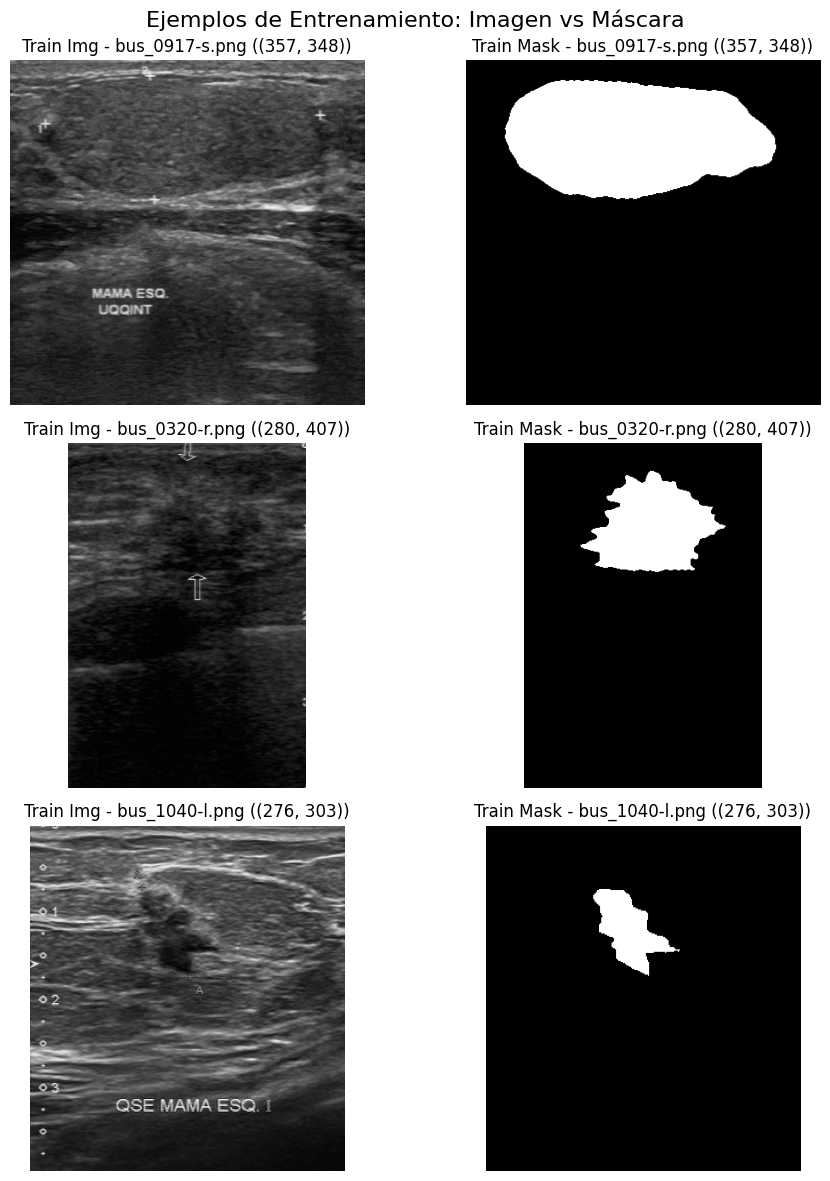

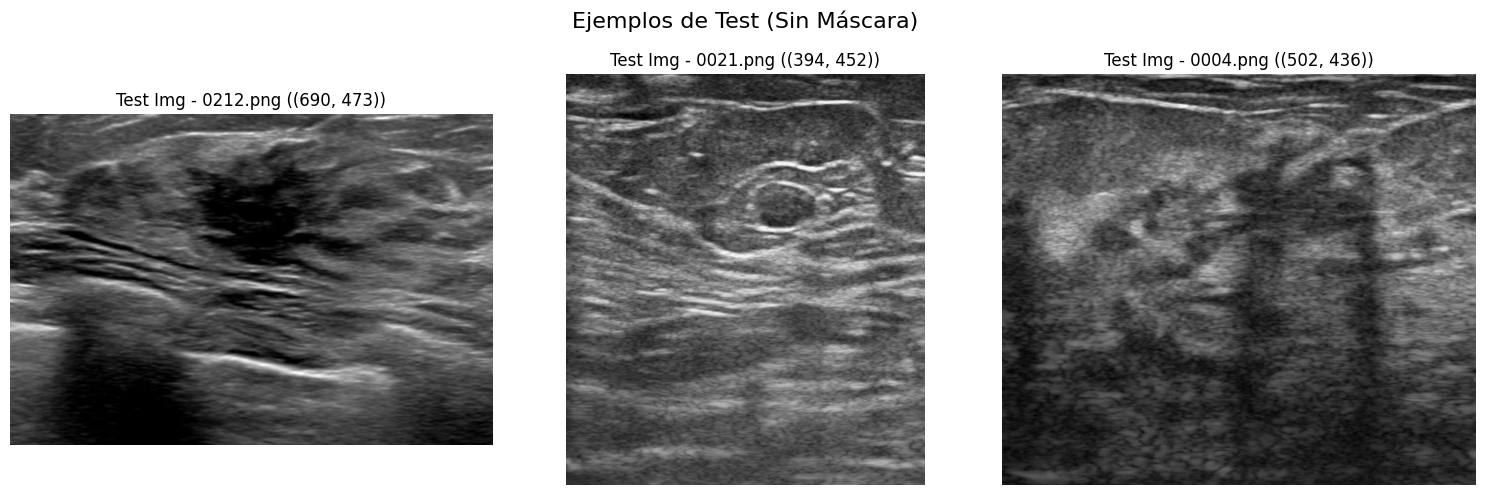

In [ ]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# Seleccionar índices aleatorios
random.seed(SEED)
num_samples = 3
train_indices = random.sample(range(len(train_images)), num_samples)
test_indices = random.sample(range(len(test_images)), num_samples)

# Graficar imágenes de entrenamiento y sus máscaras
fig, axes = plt.subplots(num_samples, 2, figsize=(10, num_samples * 4))
plt.suptitle("Ejemplos de Entrenamiento: Imagen vs Máscara", fontsize=16)
for i, idx in enumerate(train_indices):
    img = Image.open(train_images[idx]).convert("L")
    mask = Image.open(train_masks[idx]).convert("L")

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"Train Img - {Path(train_images[idx]).name} ({img.size})")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(f"Train Mask - {Path(train_masks[idx]).name} ({mask.size})")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

# Graficar imágenes de test
fig, axes = plt.subplots(1, num_samples, figsize=(15, 5))
plt.suptitle("Ejemplos de Test (Sin Máscara)", fontsize=16)
for i, idx in enumerate(test_indices):
    img = Image.open(test_images[idx]).convert("L")
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Test Img - {Path(test_images[idx]).name} ({img.size})")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from PIL import Image

def analyze_resolutions(image_paths, dataset_name):
    widths = []
    heights = []

    for path in image_paths:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)

    widths = np.array(widths)
    heights = np.array(heights)

    print(f"=== Análisis de Resoluciones: {dataset_name} ===")
    print(f"Total de imágenes: {len(image_paths)}")
    print(f"Ancho (Width):  Min={widths.min()}, Max={widths.max()}, Promedio={widths.mean():.1f}, Mediana={np.median(widths)}")
    print(f"Alto (Height):  Min={heights.min()}, Max={heights.max()}, Promedio={heights.mean():.1f}, Mediana={np.median(heights)}")

    # Mostrar las 5 resoluciones más comunes
    resolutions = [f"{w}x{h}" for w, h in zip(widths, heights)]
    most_common = Counter(resolutions).most_common(5)
    print("Resoluciones más comunes:")
    for res, count in most_common:
        print(f"  - {res}: {count} imágenes ({count/len(image_paths)*100:.1f}%)")
    print("\n")

analyze_resolutions(train_images, "Entrenamiento (Train)")
analyze_resolutions(test_images, "Prueba (Test)")

=== Análisis de Resoluciones: Entrenamiento (Train) ===
Total de imágenes: 1875
Ancho (Width):  Min=240, Max=579, Promedio=321.3, Mediana=286.0
Alto (Height):  Min=268, Max=478, Promedio=391.3, Mediana=383.0
Resoluciones más comunes:
  - 276x305: 29 imágenes (1.5%)
  - 276x304: 26 imágenes (1.4%)
  - 276x369: 21 imágenes (1.1%)
  - 322x434: 20 imágenes (1.1%)
  - 323x433: 20 imágenes (1.1%)


=== Análisis de Resoluciones: Prueba (Test) ===
Total de imágenes: 252
Ancho (Width):  Min=353, Max=967, Promedio=558.0, Mediana=494.5
Alto (Height):  Min=251, Max=609, Promedio=473.4, Mediana=471.5
Resoluciones más comunes:
  - 423x450: 1 imágenes (0.4%)
  - 666x492: 1 imágenes (0.4%)
  - 436x510: 1 imágenes (0.4%)
  - 566x444: 1 imágenes (0.4%)
  - 502x436: 1 imágenes (0.4%)




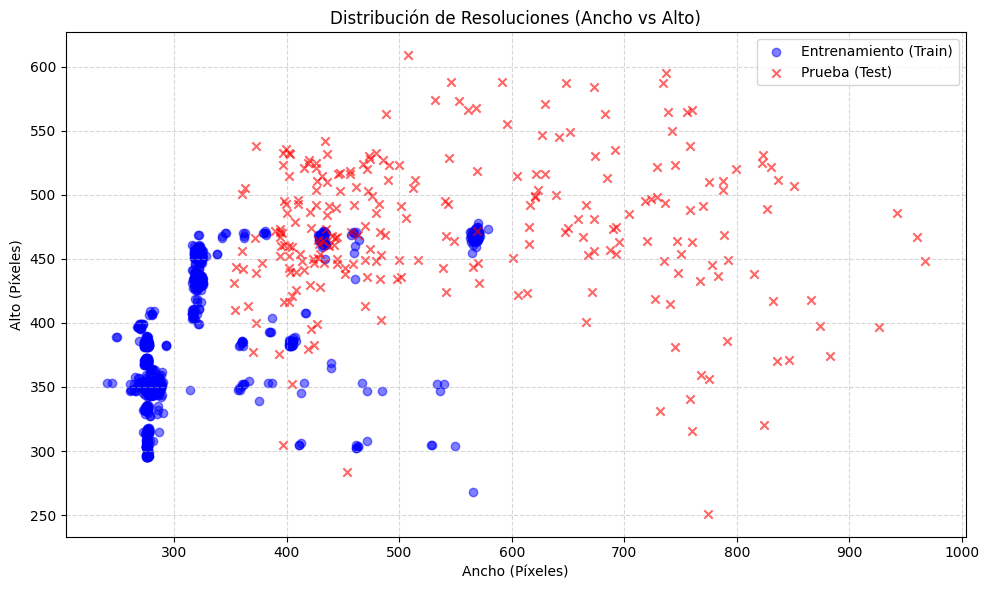

In [ ]:


def get_dimensions(image_paths):
    widths = []
    heights = []
    for path in image_paths:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
    return widths, heights

# Obtener dimensiones
train_w, train_h = get_dimensions(train_images)
test_w, test_h = get_dimensions(test_images)

# Crear el gráfico
plt.figure(figsize=(10, 6))
plt.scatter(train_w, train_h, alpha=0.5, label='Entrenamiento (Train)', color='blue')
plt.scatter(test_w, test_h, alpha=0.6, label='Prueba (Test)', color='red', marker='x')

plt.title('Distribución de Resoluciones (Ancho vs Alto)')
plt.xlabel('Ancho (Píxeles)')
plt.ylabel('Alto (Píxeles)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

###Transformación

In [ ]:
import torchvision.transforms as transforms

# Definimos el tamaño estándar al que llevaremos todas las imágenes
IMG_SIZE = 512

# 1. Transformaciones básicas para Validación y Test (sin aumentación aleatoria)
transform_val = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

# 2. Transformaciones con Aumento de Datos (Data Augmentation) para Entrenamiento
transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

print("Transformaciones ajustadas correctamente con Resize activo.")

Transformaciones ajustadas correctamente con Resize activo.


In [ ]:
import random
from pathlib import Path
from PIL import Image
import torch
import torchvision.transforms as transforms

class Dataset(Dataset):
    def __init__(self, image_paths, mask_paths=None, transform_type='val', is_test=False):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform_type = transform_type  # 'train' o 'val'
        self.is_test = is_test

        if not self.is_test:
            assert len(self.image_paths) == len(self.mask_paths), "La cantidad de imágenes y máscaras debe ser igual."

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Cargar imagen en escala de grises (L)
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("L")

        if self.is_test:
            # Para test aplicamos únicamente la transformación de validación
            image = transform_val(image)
            return image, Path(img_path).name

        # Cargar máscara en escala de grises (L)
        mask_path = self.mask_paths[idx]
        mask = Image.open(mask_path).convert("L")

        if self.transform_type == 'train':
            # Guardamos el estado aleatorio actual para sincronizar la imagen y la máscara
            state = torch.get_rng_state()
            state_random = random.getstate()

            # Aplicamos transform_train a la imagen
            image = transform_train(image)

            # Restauramos el estado aleatorio original para que la máscara reciba la misma transformación
            torch.set_rng_state(state)
            random.setstate(state_random)

            # Transformaciones geométricas para la máscara (incluyendo redimensionado)
            mask_transforms = transforms.Compose([
                transforms.Resize((IMG_SIZE, IMG_SIZE)),
                transforms.ToTensor()
            ])
            mask = mask_transforms(mask)
        else:
            # Para validación aplicamos las transformaciones sin aumentación
            image = transform_val(image)

            mask_transforms = transforms.Compose([
                transforms.Resize((IMG_SIZE, IMG_SIZE)),
                transforms.ToTensor()
            ])
            mask = mask_transforms(mask)

        # Binarizamos la máscara (0.0 o 1.0)
        mask = (mask > 0.5).float()

        return image, mask

In [ ]:
# Instanciar los conjuntos de datos utilizando la clase unificada
train_dataset = Dataset(train_images, train_masks, transform_type='train', is_test=False)
test_dataset = Dataset(test_images, is_test=True)

print(f"Dataset de entrenamiento creado con transform_train: {len(train_dataset)} muestras.")
print(f"Dataset de prueba creado con transform_val: {len(test_dataset)} muestras.")

Dataset de entrenamiento creado con transform_train: 1875 muestras.
Dataset de prueba creado con transform_val: 252 muestras.


In [ ]:
from sklearn.model_selection import train_test_split

# 1. Dividimos las listas originales de rutas de imágenes y máscaras en train y val
train_imgs_split, val_imgs_split, train_masks_split, val_masks_split = train_test_split(
    train_images,
    train_masks,
    test_size=0.15,
    random_state=SEED
)

# 2. Instanciamos los datasets correspondientes con sus respectivas transformaciones
train_dataset = Dataset(train_imgs_split, train_masks_split, transform_type='train', is_test=False)
val_dataset = Dataset(val_imgs_split, val_masks_split, transform_type='val', is_test=False)

print(f"Dataset de Entrenamiento: {len(train_dataset)} muestras")
print(f"Dataset de Validación: {len(val_dataset)} muestras")

Dataset de Entrenamiento: 1593 muestras
Dataset de Validación: 282 muestras


In [ ]:
from torch.utils.data import Subset

def make_loader(dataset, shuffle=False):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS)

train_loader = make_loader(train_dataset, shuffle=True)
val_loader = make_loader(val_dataset)
test_loader = make_loader(test_dataset)

# submuestra fija de train
rng = np.random.RandomState(SEED)
train_eval_idx = rng.choice(len(train_dataset), size=1000, replace=False).tolist()
train_eval_loader = make_loader(Subset(train_dataset, train_eval_idx))

x_batch, y_batch = next(iter(train_dataset))
print(f"Batch de train: x {tuple(x_batch.shape)} {x_batch.dtype} | y {tuple(y_batch.shape)} {y_batch.dtype}")

Batch de train: x (1, 512, 512) torch.float32 | y (1, 512, 512) torch.float32


###Módelo

In [ ]:
class Block(nn.Module):
    def __init__(self, inChannels, outChannels):
        super().__init__()
        # Almacenar las capas de convolución y activación utilizando el prefijo nn
        self.conv1 = nn.Conv2d(inChannels, outChannels, 3)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(outChannels, outChannels, 3)

    def forward(self, x):
        # Aplicar CONV => RELU => CONV al bloque de entrada y retornarlo
        return self.conv2(self.relu(self.conv1(x)))

In [ ]:
class Encoder(nn.Module):
    def __init__(self, channels=(1, 16, 32, 64)):
        super().__init__()
        # Almacenar los bloques de codificación y la capa de maxpooling
        # Cambiamos el canal inicial a 1 porque trabajamos con escala de grises
        self.encBlocks = nn.ModuleList([
            Block(channels[i], channels[i + 1])
            for i in range(len(channels) - 1)
        ])
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        # Inicializar una lista para almacenar los mapas de características intermedias (para las Skip Connections)
        blockOutputs = []

        # Pasar la entrada a través de los bloques del encoder
        for block in self.encBlocks:
            x = block(x)
            blockOutputs.append(x)
            x = self.pool(x)

        # Retornar la lista con las salidas intermedias
        return blockOutputs

In [ ]:
from torchvision.transforms import CenterCrop

class Decoder(nn.Module):
    def __init__(self, channels=(64, 32, 16)):
        super().__init__()
        # Inicializar canales, bloques de upsampling (convolución transpuesta) y decodificación
        self.channels = channels
        self.upconvs = nn.ModuleList([
            nn.ConvTranspose2d(channels[i], channels[i + 1], 2, 2)
            for i in range(len(channels) - 1)
        ])
        self.dec_blocks = nn.ModuleList([
            Block(channels[i], channels[i + 1])
            for i in range(len(channels) - 1)
        ])

    def forward(self, x, encFeatures):
        # Iterar a través de las etapas del Decoder
        for i in range(len(self.channels) - 1):
            # 1. Aplicar la Convolución Transpuesta para duplicar dimensiones espaciales
            x = self.upconvs[i](x)

            # 2. Recortar la skip connection correspondiente (del Encoder) para que coincida en tamaño
            encFeat = self.crop(encFeatures[i], x)

            # 3. Concatenar a lo largo del eje de canales
            x = torch.cat([x, encFeat], dim=1)

            # 4. Pasar por el bloque de doble convolución
            x = self.dec_blocks[i](x)

        return x

    def crop(self, encFeatures, x):
        # Obtener dimensiones espaciales del tensor objetivo x
        (_, _, H, W) = x.shape
        # Aplicar el recorte de tamaño (H, W) en el centro
        encFeatures = CenterCrop([H, W])(encFeatures)
        return encFeatures

In [ ]:
class UNet(nn.Module):
    def __init__(self, encChannels=(1, 16, 32, 64),
                 decChannels=(64, 32, 16),
                 nbClasses=1, retainDim=True,
                 outSize=(512, 512)):
        super().__init__()
        # Inicializar el codificador (Encoder) y el decodificador (Decoder)
        self.encoder = Encoder(encChannels)
        self.decoder = Decoder(decChannels)

        # Capa de convolución final (clasificador/head de segmentación)
        self.head = nn.Conv2d(decChannels[-1], nbClasses, 1)
        self.retainDim = retainDim
        self.outSize = outSize

    def forward(self, x):
        # 1. Obtener los mapas de características del Encoder (Skip Connections)
        encFeatures = self.encoder(x)

        # 2. Pasar el último mapa de características al Decoder junto con las skip connections
        # Nota: Invertimos el orden de las conexiones para que coincidan con la profundidad del decoder
        decFeatures = self.decoder(encFeatures[-1], encFeatures[::-1][1:])

        # 3. Clasificación píxel a píxel con la capa head
        mapa = self.head(decFeatures)

        # 4. Redimensionar el mapa de características al tamaño original si está activo retainDim
        if self.retainDim:
            mapa = F.interpolate(mapa, self.outSize, mode="bilinear", align_corners=False)

        return mapa

In [ ]:
# Resumen de la arquitectura del modelo U-Net utilizando torchinfo
summary(UNet(outSize=(IMG_SIZE, IMG_SIZE)).to(DEVICE), input_size=(BATCH_SIZE, 1, IMG_SIZE, IMG_SIZE))

Layer (type:depth-idx)                   Output Shape              Param #
UNet                                     [64, 1, 512, 512]         --
├─Encoder: 1-1                           [64, 16, 508, 508]        --
│    └─ModuleList: 2-5                   --                        (recursive)
│    │    └─Block: 3-1                   [64, 16, 508, 508]        2,480
│    └─MaxPool2d: 2-2                    [64, 16, 254, 254]        --
│    └─ModuleList: 2-5                   --                        (recursive)
│    │    └─Block: 3-2                   [64, 32, 250, 250]        13,888
│    └─MaxPool2d: 2-4                    [64, 32, 125, 125]        --
│    └─ModuleList: 2-5                   --                        (recursive)
│    │    └─Block: 3-3                   [64, 64, 121, 121]        55,424
│    └─MaxPool2d: 2-6                    [64, 64, 60, 60]          --
├─Decoder: 1-2                           [64, 16, 472, 472]        --
│    └─ModuleList: 2-9                   --    

In [ ]:
LR = 1e-3
EPOCHS = 35
PATIENCE = 5
WEIGHT_DECAY = 1e-4
DROPOUT = 0.2

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

def dice_coefficient(y_true, y_pred, smooth=1e-6):
    # y_true y y_pred son tensores con valores binarios (0 o 1)
    intersection = (y_true * y_pred).sum()
    return (2. * intersection + smooth) / (y_true.sum() + y_pred.sum() + smooth)

@torch.no_grad()
def predict_masks(model, loader, device=DEVICE):
    model.eval()
    preds, targets = [], []
    for x, y in loader:
        x = x.to(device)
        # Pasar por el modelo y aplicar sigmoide
        logits = model(x)
        probs = torch.sigmoid(logits)
        # Binarizar predicciones con umbral 0.5
        pred_masks = (probs > 0.5).float().cpu()

        preds.append(pred_masks)
        targets.append(y.cpu())

    return torch.cat(preds, dim=0), torch.cat(targets, dim=0)

def run_experiment(name, lr=LR, epochs=EPOCHS, patience=PATIENCE, weight_decay=WEIGHT_DECAY):
    # Inicializar el modelo UNet para escala de grises y 1 canal de salida
    model = UNet(outSize=(IMG_SIZE, IMG_SIZE)).to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    # Pérdida estándar para segmentación binaria
    criterion = nn.BCEWithLogitsLoss()

    print(f"Iniciando experimento: {name}")

    hist = {"train_loss": [], "val_loss": [], "val_dice": []}

    def log_fn(epoch, train_loss, val_loss):
        # Evaluar métricas adicionales en validación
        preds, targets = predict_masks(model, val_loader)
        dice_score = dice_coefficient(targets, preds).item()

        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)
        hist["val_dice"].append(dice_score)

        print(f"  Época {epoch + 1:02d} | train_loss={train_loss:.4f} val_loss={val_loss:.4f} | val_Dice={dice_score:.4f}")

    start = time.perf_counter()
    train_errors, val_errors = train(
        model=model,
        optimizer=optimizer,
        criterion=criterion,
        train_loader=train_loader,
        val_loader=val_loader,
        device=DEVICE,
        do_early_stopping=True,
        patience=patience,
        restore_best=True,
        epochs=epochs,
        log_fn=log_fn,
        log_every=1,
    )
    train_time = time.perf_counter() - start

    # Evaluación final con el mejor modelo
    preds, targets = predict_masks(model, val_loader)
    best_dice = dice_coefficient(targets, preds).item()

    result = {
        "name": name,
        "model": model,
        "train_losses": train_errors,
        "val_losses": val_errors,
        "val_dices": hist["val_dice"],
        "best_epoch": int(np.argmin(val_errors)) + 1,
        "n_epochs": len(val_errors),
        "train_time_sec": train_time,
        "best_val_dice": best_dice,
    }

    print(f"=> {name} finalizado: mejor época {result['best_epoch']} de {result['n_epochs']} | val_Dice={best_dice:.4f} | tiempo={train_time:.0f}s")
    return result

def plot_history(res):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Gráfico de Pérdidas
    axes[0].plot(range(1, len(res["train_losses"]) + 1), res["train_losses"], label="Train Loss")
    axes[0].plot(range(1, len(res["val_losses"]) + 1), res["val_losses"], label="Val Loss")
    axes[0].axvline(res["best_epoch"], color="gray", linestyle="--", label=f"Mejor época ({res['best_epoch']})")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Pérdida - {res['name']}")
    axes[0].legend()
    axes[0].grid(True)

    # Gráfico de Coeficiente Dice
    axes[1].plot(range(1, len(res["val_dices"]) + 1), res["val_dices"], label="Val Dice", color="green")
    axes[1].axvline(res["best_epoch"], color="gray", linestyle="--")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Dice Coefficient")
    axes[1].set_title(f"Métrica Dice de Validación - {res['name']}")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

results = {}


In [ ]:
# 1. Ejecutar el experimento de entrenamiento para la U-Net
experiment_results = run_experiment(name="UNet_Baseline_Experiment")

# 2. Guardar los resultados en el diccionario global
results["UNet_Baseline"] = experiment_results

# 3. Imprimir el resumen final de los resultados obtenidos
print("\n=== RESUMEN DE RESULTADOS ===")
print(f"Modelo: {experiment_results['name']}")
print(f"Mejor Época: {experiment_results['best_epoch']}")
print(f"Dice Coef. en Validación: {experiment_results['best_val_dice']:.4f}")
print(f"Tiempo de Entrenamiento: {experiment_results['train_time_sec']:.2f} segundos")

# 4. Mostrar las curvas de entrenamiento y validación
plot_history(experiment_results)

Iniciando experimento: UNet_Baseline_Experiment
